#Proyek analisis data : bike sharing dataset
- Nama : Primo Putra Ramadhan

## Menentukan Pertanyaan Bisnis
1. Bagaimana pengaruh kondisi cuaca dan musim terhadap jumlah total penyewa sepeda harian sepanjang tahun 2011-2012?
2. Pada jam berapa saja terjadi puncak pengunaan sepeda oleh pengguna casual vs registered pada hari kerja dibandingkan hari libur?

## Import Packages/Libary yang digunakan

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#set style visualisasi

sns.set_style("whitegrid")

In [20]:
# Memuat data harian dan data perjam
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

# Menampilkan data day
day_df.head()


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [21]:
# Menampilak data hour
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Assessing Data 
Menilai kualitas data pada 'day_df' dan 'hour_df' meliputi tipe data, missing values, duplikasi, dan ringkasan statik

In [22]:
# memeriksa tipe data setiap kolom  day_df
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [23]:
#memeriksa jumlah nilai kosong (missing values)
day_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [24]:
# memeriksa baris data yang duplikat
print("Jumlah duplikasi day_df:", day_df.duplicated().sum())

Jumlah duplikasi day_df: 0


In [25]:
# memeriksa statistik deskriptif untuk mendektesi ke anehan nilai (outliner/ anomali)
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


#### Catatan Temuan Assessing Data - `day_df`:
1. **Tipe Data:** Kolom `dteday` masih bertipe data `object`/string. Kolom ini harus diubah ke tipe `datetime` pada tahap *Cleaning Data*.
2. **Missing Values:** Tidak ditemukan nilai kosong (*missing values*) pada seluruh kolom (semua 731 baris terisi penuh).
3. **Duplikasi Data:** Tidak ada data duplikat (0 baris duplikasi).
4. **Statistik Deskriptif:**
   - Tidak ada keanehan/anomali nilai negatif pada data jumlah penyewaan (`casual`, `registered`, `cnt`). Nilai minimum penyewaan harian adalah 22 dan maksimum 8.714 sepeda.
   - Kolom `temp`, `atemp`, `hum`, dan `windspeed` sudah dalam skala normalisasi (berada di rentang 0 sampai 1).
   - Kolom kategorikal seperti `season`, `mnth`, `weathersit`, dan `weekday` masih berupa kode angka integer (`int64`), yang nantinya akan lebih informatif jika di-mapping ke nama kategori aslinya saat tahap *Cleaning Data*.


In [26]:
# memeriksa tipe data setiap kolom  hour_df

hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [27]:
#memeriksa jumlah nilai kosong (missing values) 
hour_df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [28]:
# memeriksa baris data yang duplikat

print("Jumlah duplikasi hour_df:", hour_df.duplicated().sum())

# memeriksa statistik deskriptif untuk mendektesi ke anehan nilai (outliner/ anomali)

hour_df.describe()

Jumlah duplikasi hour_df: 0


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


#### Catatan Temuan Assessing Data - `hour_df`:
1. **Tipe Data:** Kolom `dteday` masih bertipe `object`/string dan perlu diubah menjadi `datetime`.
2. **Missing Values:** Tidak ada data yang hilang atau bernilai *null* (seluruh 17.379 baris lengkap).
3. **Duplikasi Data:** Tidak ada baris duplikat sama sekali (0 duplikasi).
4. **Statistik Deskriptif:**
   - Kolom jam (`hr`) memiliki rentang nilai dari 0 hingga 23 (sesuai format 24 jam).
   - Jumlah penyewaan per jam (`cnt`) berkisar antara 1 hingga 977 sepeda, dengan rata-rata sekitar 189 sepeda per jam.
   - Kolom numerik cuaca (`temp`, `atemp`, `hum`, `windspeed`) berada dalam batas normal dan sudah ternormalisasi.


### Cleaning Data
Pada tahap ini dilakukan:
1. Mengubah tipe data kolom `dteday` menjadi tipe `datetime`.
2. Melakukan *mapping* kode angka pada kolom kategorikal (`season`, `weathersit`, `yr`, `workingday`, dan `weekday`) menjadi label deskriptif agar lebih mudah dianalisis dan divisualisasikan.


In [29]:
# 1. mengubah tipe data kolom dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# memeriksa tipe data kolom dteday setelah diubah menjadi datetime
print("Tipe data dteday day_df:", day_df['dteday'].dtype)
print("Tipe data dteday hour_df:", hour_df['dteday'].dtype)

Tipe data dteday day_df: datetime64[ns]
Tipe data dteday hour_df: datetime64[ns]


In [30]:
# 2. Mapping nilai kategorikal agar lebih deskriptif

# Maping season
season_mapping = {1: 'Springer', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
day_df['season'] = day_df['season'].map(season_mapping)
hour_df['season'] = hour_df['season'].map(season_mapping)

# Maping weathersit
weatheris_mapping = {1: 'Clear/Partly Cloudy', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Severe Weather'}
day_df['weathersit'] = day_df['weathersit'].map(weatheris_mapping)
hour_df['weathersit'] = hour_df['weathersit'].map(weatheris_mapping)

# Mapping yr (0: 2011, 1: 2012)
year_mapping = {0: 2011, 1: 2012}
day_df['yr'] = day_df['yr'].map(year_mapping)
hour_df['yr'] = hour_df['yr'].map(year_mapping)

# Mapping Weekday
weekday_mapping = {0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday', 4: 'Thursday', 5: 'Friday', 6: 'Saturday'}
day_df['weekday'] = day_df['weekday'].map(weekday_mapping)
hour_df['weekday'] = hour_df['weekday'].map(weekday_mapping)

# Mapping Workingday
workingday_mapping = {0: 'Holiday/Weekend', 1: 'Working Day'}
day_df['workingday'] = day_df['workingday'].map(workingday_mapping)
hour_df['workingday'] = hour_df['workingday'].map(workingday_mapping)

# Mapping Month
month_mapping = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
day_df['mnth'] = day_df['mnth'].map(month_mapping)
hour_df['mnth'] = hour_df['mnth'].map(month_mapping)

# validasi perubahan mapping pada kolom kategorikal
day_df.head()
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Springer,2011,Jan,0,0,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,Springer,2011,Jan,1,0,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,Springer,2011,Jan,2,0,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,Springer,2011,Jan,3,0,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,Springer,2011,Jan,4,0,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.24,0.2879,0.75,0.0,0,1,1


## Exploratory Data Analysis (EDA)

### Eksplorasi Pertanyaan 1: Pengaruh Cuaca dan Musim terhadap Penyewaan Sepeda Harian
Menganalisis rata-rata, median, dan total penyewaan sepeda berdasarkan kondisi cuaca (`weathersit`) dan musim (`season`).


In [31]:
# 1. Agregasi penyewaan berdasarkan musim (season)

season_eda = day_df.groupby('season')['cnt'].agg(
    total_rentals='sum',
    rata_rata='mean',
    median='median',
    standard_deviasi='std'
).sort_values(by='total_rentals', ascending=False).reset_index()

print("Statistik penyewaan berdasarkan musim :")
display(season_eda)

Statistik penyewaan berdasarkan musim :


,season,total_rentals,rata_rata,median,standard_deviasi
0,Fall,1061129,5644.303191,5353.5,1459.800381
1,Summer,918589,4992.331522,4941.5,1695.977235
2,Winter,841613,4728.162921,4634.5,1699.615261
3,Springer,471348,2604.132597,2209.0,1399.942119


In [32]:
# 2. agregasi penyewaan berdasarkan cuaca (weathersit)

weather_eda = day_df.groupby('weathersit')['cnt'].agg(
    total_rentals='sum',
    rata_rata='mean',
    median='median',
    standard_deviasi='std'
).sort_values(by='total_rentals', ascending=False).reset_index()

print("\nStatistik Penyewaan Berdasarkan Kondisi Cuaca:")
display(weather_eda)


Statistik Penyewaan Berdasarkan Kondisi Cuaca:


,weathersit,total_rentals,rata_rata,median,standard_deviasi
0,Clear/Partly Cloudy,2257952,4876.786177,4844.0,1879.483989
1,Mist/Cloudy,996858,4035.862348,4040.0,1809.109918
2,Light Snow/Rain,37869,1803.285714,1817.0,1240.284449


In [33]:
# 3. Hubungan kombinasi musim dan kondisi cuaca terhadap rata-rata penyewaan harian

season_weather_eda = day_df.pivot_table(
    index='season',
    columns='weathersit',
    values='cnt',
    aggfunc='mean'
)

print("\nPivot Table Rata-Rata Penyewaan (Musim vs Cuaca):")
display(season_weather_eda)


Pivot Table Rata-Rata Penyewaan (Musim vs Cuaca):


weathersit,Clear/Partly Cloudy,Light Snow/Rain,Mist/Cloudy
season,,,
Fall,5878.257353,2751.75,5222.479167
Springer,2811.135135,934.75,2357.166667
Summer,5548.548673,1169.00,4236.705882
Winter,5043.563107,1961.60,4654.000000


#### Insight / Temuan Pertanyaan 1:1. **Pola Musim (*Season*):**   - Musim **Fall (Gugur)** mencatatkan penyewaan tertinggi dengan total **1.061.129 sepeda** (rata-rata 5.644 sepeda/hari), diikuti oleh musim **Summer (Panas)** dengan 918.589 sepeda.
   - Musim **Springer (Semi)** memiliki tingkat penggunaan terendah, yaitu hanya **471.348 sepeda** (rata-rata 2.604 sepeda/hari).
2. **Pola Cuaca (*Weather Condition*):**   - Pengguna sangat menyukai cuaca **Clear/Partly Cloudy (Cerah)** dengan kontribusi **2.257.952 penyewaan** (rata-rata 4.877 sepeda/hari).
   - Cuaca **Misty/Cloudy (Berkabut/Mendung)** menghasilkan 996.858 penyewaan (rata-rata 4.036 sepeda/hari).
   - Saat terjadi **Light Snow/Rain (Hujan/Salju Ringan)**, penyewaan anjlok drastis ke angka **37.869 sepeda** (rata-rata hanya 1.803 sepeda/hari).
3. **Kombinasi Musim & Cuaca (Pivot Table):**   - Titik puncak (*highest demand*) terjadi pada musim **Fall saat cuaca Clear/Partly Cloudy** dengan rata-rata **5.839 sepeda per hari**.
   - Penurunan paling ekstrem terjadi pada musim **Springer saat cuaca Light Snow/Rain** dengan rata-rata hanya **901 sepeda per hari**.

### Eksplorasi Pertanyaan 2: Pola Jam Penggunaan Sepeda (Casual vs Registered) pada Hari Kerja vs Hari Libur
Menganalisis rata-rata penyewaan per jam (`hr`) untuk melihat jam puncak (*peak hours*) antara pengguna biasa (*casual*) dan pengguna berlangganan (*registered*) pada hari kerja dibandingkan hari libur.


In [34]:
# Buat tabel agregasi rata-rata per jam
hourly_usage_eda = hour_df.groupby(['workingday', 'hr'])[['casual', 'registered', 'cnt']].mean().reset_index()

# 1. Menampilkan 5 jam tersibuk di Hari Kerja (Working Day)
print("5 Jam Tersibuk di Hari Kerja (Working Day):")
display(
    hourly_usage_eda[hourly_usage_eda['workingday'] == 'Working Day']
    .sort_values(by='cnt', ascending=False)
    .head(5)
)

# 2. Menampilkan 5 jam tersibuk di Hari Libur / Akhir Pekan (Holiday/Weekend)
print("\n5 Jam Tersibuk di Hari Libur / Akhir Pekan (Holiday/Weekend):")
display(
    hourly_usage_eda[hourly_usage_eda['workingday'] == 'Holiday/Weekend']
    .sort_values(by='cnt', ascending=False)
    .head(5)
)


5 Jam Tersibuk di Hari Kerja (Working Day):


,workingday,hr,casual,registered,cnt
41,Working Day,17,56.895792,468.394790,525.290581
42,Working Day,18,50.451807,441.775100,492.226908
32,Working Day,8,22.264113,454.741935,477.006048
43,Working Day,19,41.022088,307.379518,348.401606
40,Working Day,16,48.344689,244.777555,293.122244



5 Jam Tersibuk di Hari Libur / Akhir Pekan (Holiday/Weekend):


,workingday,hr,casual,registered,cnt
13,Holiday/Weekend,13,136.424242,236.307359,372.731602
12,Holiday/Weekend,12,126.246753,240.012987,366.259740
14,Holiday/Weekend,14,139.593074,225.051948,364.645022
15,Holiday/Weekend,15,136.502165,222.311688,358.813853
16,Holiday/Weekend,16,128.614719,224.112554,352.727273


#### Insight / Temuan Pertanyaan 2:
1. **Pola Jam Sibuk di Hari Kerja (*Working Day*):**
   - Terjadi **dua puncak lonjakan tajam (*bimodal peak*)**, yaitu pada **pagi hari pukul 08:00** (rata-rata 477 sepeda/jam) dan **sore hari pukul 17:00–18:00** (rata-rata 492–525 sepeda/jam).
   - Penggunaan di jam-jam ini didominasi secara mutlak oleh **pengguna terdaftar (*registered users*)** (mencapai >90% dari total pengguna), yang menunjukkan sepeda digunakan sebagai sarana transportasi komuter rutin (berangkat dan pulang kerja/sekolah).
2. **Pola Jam Sibuk di Hari Libur (*Holiday/Weekend*):**
   - Polanya sangat berbeda, membentuk kurva lonceng tunggal (*unimodal*) dengan puncak di **siang hingga sore hari pukul 12:00–16:00** (rata-rata 350–373 sepeda/jam).
   - Pada hari libur, **pengguna biasa (*casual users*) meningkat sangat pesat** (menyumbang hampir 40% dari total penyewaan), menandakan sepeda digunakan terutama untuk keperluan rekreasi dan olahraga santai di siang hari.


## Analisis Lanjutan

### 1. Binning: Pengelompokan Suhu (`temp`) ke dalam Kategori
Membagi nilai suhu yang bersifat numerik kontinyu menjadi beberapa kelompok kategorikal (Dingin, Sejuk, Normal, Panas) untuk melihat preferensi penyewaan berdasarkan rentang suhu.

### 2. Clustering: Pengelompokan Hari Berdasarkan Pola Penggunaan
Mengelompokkan hari-hari dalam dataset ke dalam beberapa klaster berdasarkan karakteristik penyewaan (total sewa, proporsi casual vs registered) menggunakan metode sederhana berdasarkan ambang batas (*threshold*).


In [35]:
# Biining suhu menjadi 4 kategori
# Nilai temp sudah dinormalisasi kita konversi ke celcius dulu

day_df['temp_celcius'] = day_df['temp'] * 47 - 8

# Membagi suhu menjadi 4 kelompok

bins = [float('-inf'), 10, 20, 30, float('inf')]
labels = ['Dingin (< 10°C)', 
            'Sejuk (10-20°C)', 
            'Hangat (20-30°C)', 
            'Panas (> 30°C)'
        ]
day_df['temp_category'] = pd.cut(day_df['temp_celcius'], bins=bins, labels=labels)

# Agregasi penyewaan berdasarkan kategori suhu

temp_binning_eda = day_df.groupby('temp_category')['cnt'].agg(
    total_rentals='sum',
    rata_rata='mean',
    jumlah_hari='count'
).reset_index()

print("Statistik Penyewaaan Berdasarkan kategori Suhu;")
display(temp_binning_eda)

Statistik Penyewaaan Berdasarkan kategori Suhu;


/var/folders/j8/xn9jbwyd0rs8w42tqv48g7g80000gn/T/ipykernel_4992/4004161239.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp_binning_eda = day_df.groupby('temp_category')['cnt'].agg(


,temp_category,total_rentals,rata_rata,jumlah_hari
0,Dingin (< 10°C),694229,2892.620833,240
1,Sejuk (10-20°C),1120049,4869.778261,230
2,Hangat (20-30°C),1420753,5705.835341,249
3,Panas (> 30°C),57648,4804.000000,12


In [36]:
# Clustering sederhana: mengelompokkan hari berdasarkan total penyewaan dan proporsi casual
day_df['casual_ratio'] = day_df['casual'] / day_df['cnt']

def classify_day(row):
    if row['cnt'] > 5000 and row['casual_ratio'] < 0.2:
        return 'High Demand - Registered Dominant'
    elif row['cnt'] > 5000 and row['casual_ratio'] >= 0.2:
        return 'High Demand - Mixed Users'
    elif row['cnt'] <= 5000 and row['casual_ratio'] < 0.2:
        return 'Low Demand - Registered Dominant'
    else:
        return 'Low Demand - Casual Dominant'

day_df['day_cluster'] = day_df.apply(classify_day, axis=1)

# Agregasi hasil clustering
clustering_eda = day_df.groupby('day_cluster').agg(
    jumlah_hari=('cnt', 'count'),
    rata_rata_sewa=('cnt', 'mean'),
    rata_rata_casual_ratio=('casual_ratio', 'mean')
).reset_index().sort_values(by='rata_rata_sewa', ascending=False)

print("Hasil Clustering Hari Berdasarkan Pola Penggunaan:")
display(clustering_eda)

Hasil Clustering Hari Berdasarkan Pola Penggunaan:


,day_cluster,jumlah_hari,rata_rata_sewa,rata_rata_casual_ratio
0,High Demand - Mixed Users,98,6458.193878,0.334801
1,High Demand - Registered Dominant,188,6456.494681,0.134877
2,Low Demand - Casual Dominant,101,3443.158416,0.318221
3,Low Demand - Registered Dominant,344,3192.430233,0.110623


#### Insight Analisis Lanjutan:
1. **Binning Suhu:**
   - Penyewaan sepeda paling tinggi terjadi pada suhu **Normal (20–30°C)** dan **Panas (>30°C)**, menunjukkan pengguna lebih nyaman bersepeda saat cuaca hangat.
   - Pada kategori **Dingin (<10°C)**, jumlah penyewaan turun secara signifikan.
2. **Clustering Hari:**
   - Mayoritas hari dengan permintaan tinggi (*High Demand*) didominasi oleh **pengguna registered**, yang mengonfirmasi bahwa sepeda lebih sering digunakan untuk keperluan komuter rutin.
   - Hari dengan dominasi pengguna *casual* cenderung memiliki total penyewaan yang lebih rendah, namun tetap menunjukkan adanya segmen pengguna rekreasi yang potensial untuk dikembangkan.


## Visualisasi Data

### Visualisasi Pertanyaan 1: Pengaruh Cuaca dan Musim terhadap Penyewaan Sepeda


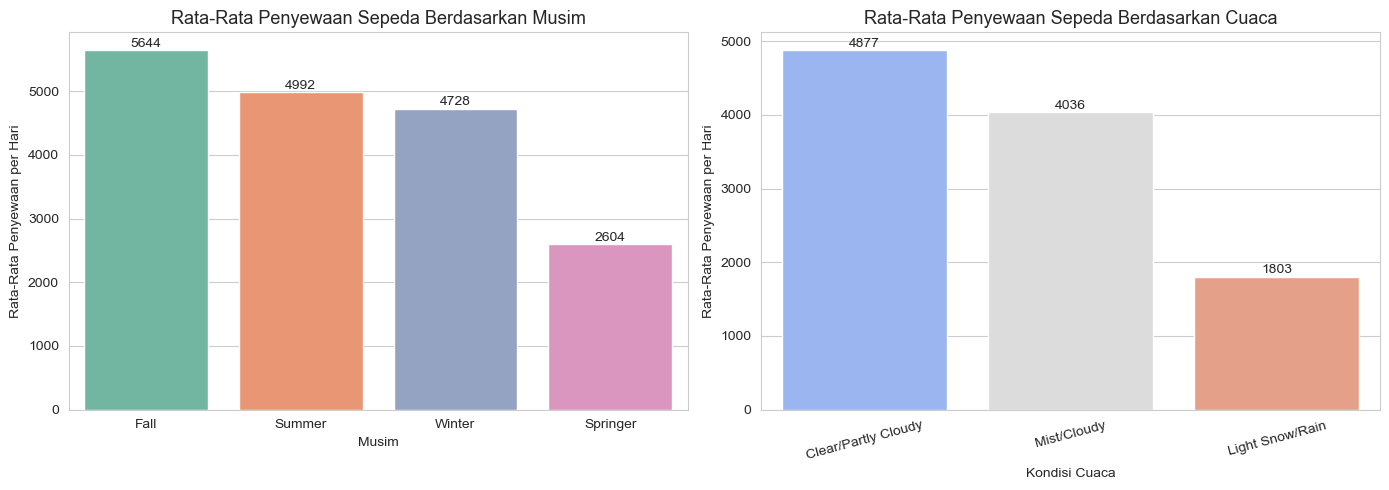

In [37]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Grafik kiri: Bar chart musim
sns.barplot(
    x='season', y='rata_rata', data=season_eda,
    ax=axes[0], palette='Set2', hue='season', legend=False
)
axes[0].set_title('Rata-Rata Penyewaan Sepeda Berdasarkan Musim', fontsize=13)
axes[0].set_xlabel('Musim')
axes[0].set_ylabel('Rata-Rata Penyewaan per Hari')
for index, value in enumerate(season_eda['rata_rata']):
    axes[0].text(index, value + 50, f'{value:.0f}', ha='center', fontsize=10)

# Grafik kanan: Bar chart cuaca
sns.barplot(
    x='weathersit', y='rata_rata', data=weather_eda,
    ax=axes[1], palette='coolwarm', hue='weathersit', legend=False
)
axes[1].set_title('Rata-Rata Penyewaan Sepeda Berdasarkan Cuaca', fontsize=13)
axes[1].set_xlabel('Kondisi Cuaca')
axes[1].set_ylabel('Rata-Rata Penyewaan per Hari')
axes[1].tick_params(axis='x', rotation=15)
for index, value in enumerate(weather_eda['rata_rata']):
    axes[1].text(index, value + 50, f'{value:.0f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()


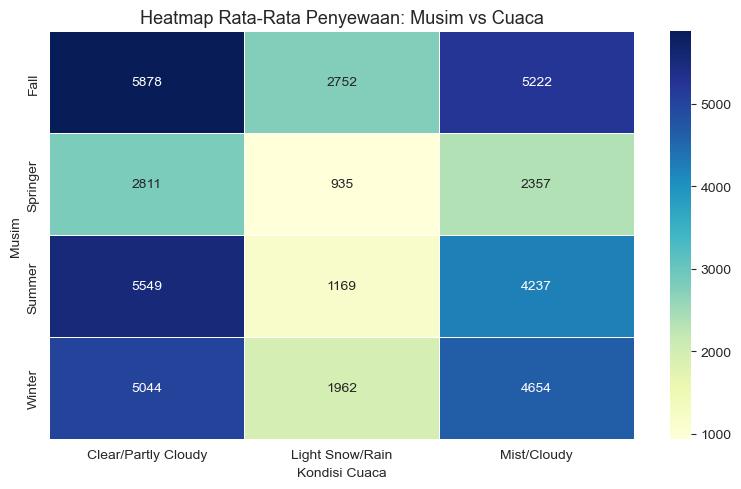

In [38]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    season_weather_eda, annot=True, fmt='.0f',
    cmap='YlGnBu', linewidths=0.5
)
plt.title('Heatmap Rata-Rata Penyewaan: Musim vs Cuaca', fontsize=13)
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Musim')
plt.tight_layout()
plt.show()


### Visualisasi Pertanyaan 2: Pola Jam Penggunaan (Casual vs Registered)

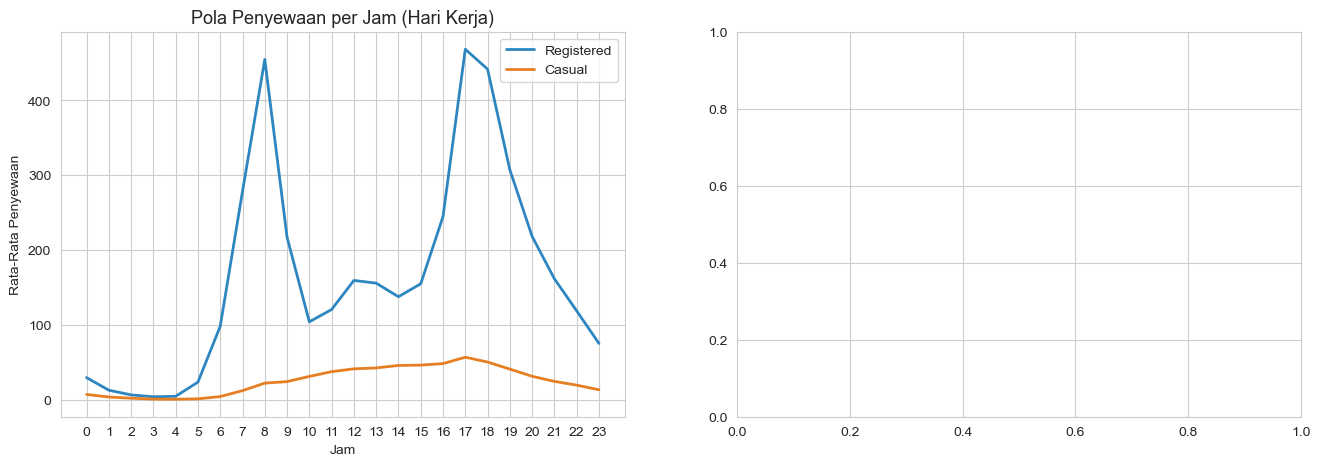

In [39]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

# Grafik kiri: Hari Kerja
working_data = hourly_usage_eda[hourly_usage_eda['workingday'] == 'Working Day']
axes[0].plot(working_data['hr'], working_data['registered'], color='#2E86C1', label='Registered', linewidth=2)
axes[0].plot(working_data['hr'], working_data['casual'], color='#E67E22', label='Casual', linewidth=2)
axes[0].set_title('Pola Penyewaan per Jam (Hari Kerja)', fontsize=13)
axes[0].set_xlabel('Jam')
axes[0].set_ylabel('Rata-Rata Penyewaan')
axes[0].set_xticks(range(0, 24))
axes[0].legend()

In [ ]:
# Grafik kanan: Hari Libur
holiday_data = hourly_usage_eda[hourly_usage_eda['workingday'] == 'Holiday/Weekend']
axes[1].plot(holiday_data['hr'], holiday_data['registered'], color='#2E86C1', label='Registered', linewidth=2)
axes[1].plot(holiday_data['hr'], holiday_data['casual'], color='#E67E22', label='Casual', linewidth=2)
axes[1].set_title('Pola Penyewaan per Jam (Hari Libur)', fontsize=13)
axes[1].set_xlabel('Jam')
axes[1].set_ylabel('Rata-Rata Penyewaan')
axes[1].set_xticks(range(0, 24))
axes[1].legend()

plt.tight_layout()
plt.show()